# Figure S9

In [1]:
from riskhistory.format import rcParams
from riskhistory.data import load_ddm_posterior, load_ddm_rhat, load_ddm_ess, DATASET_LABELS
import numpy as np
import matplotlib.pyplot as plt

DATASETS = ["equalIndifference", "equalRange", "sheng2020"]

STP_MODEL = "HDDM_Base_Lag1-full"
DRIFT_MODEL = "HDDM_Base_Lag1-full"
STIM_MODEL = "HDDM_Base_Lag1-full"

# Rhat/ESS per (model, variable), one CSV per dataset -- same source/method
# as results/analysis_ddm/hddm_compare/checking_ddm_stats.ipynb.
RHAT_BY_DATASET = {ds: load_ddm_rhat(ds) for ds in DATASETS}
ESS_BY_DATASET = {ds: load_ddm_ess(ds) for ds in DATASETS}

### Helper functions

In [2]:
def pooled_samples(model_id, dataset, param):
    """Flatten a group-level posterior parameter's 4 chains into one pooled
    sample."""
    posterior = load_ddm_posterior(model_id, dataset)
    return posterior[param].flatten()


def loss_gain_ratio_diff_samples(dataset):
    """Choice-history shift in the loss/gain drift-sensitivity ratio implied
    by the Val-CH model (STIM_MODEL, v ~ gain_centered + loss_centered +
    gain_centered:choice_prev1 + loss_centered:choice_prev1): the loss/gain
    ratio after a previous accept (+interaction) minus the same ratio after
    a previous reject (-interaction), computed per posterior draw (paired
    across the 4 terms, since they come from the same MCMC draws)."""
    posterior = load_ddm_posterior(STIM_MODEL, dataset)
    v_gain = posterior["v_gain_centered"].flatten()
    v_loss = posterior["v_loss_centered"].flatten()
    v_gain_ch = posterior["v_gain_centered:choice_prev1"].flatten()
    v_loss_ch = posterior["v_loss_centered:choice_prev1"].flatten()

    ratio_prev_accept = (v_loss + v_loss_ch) / (v_gain + v_gain_ch)
    ratio_prev_reject = (v_loss - v_loss_ch) / (v_gain - v_gain_ch)
    return ratio_prev_accept - ratio_prev_reject


def ln_bf_sign(samples):
    """ln Bayes Factor for the parameter being >0 vs. <0, from the
    (continuity-corrected) proportion of posterior mass on each side --
    equal to the posterior odds under a prior symmetric about zero."""
    n = len(samples)
    eps = 1 / (2 * n)
    p_pos = np.clip(np.mean(samples > 0), eps, 1 - eps)
    return np.log(p_pos / (1 - p_pos))


def get_convergence(model_id, dataset, param):
    """Group-level Rhat/ESS for one parameter, from the same rhat/ess CSVs
    used in results/analysis_ddm/hddm_compare/checking_ddm_stats.ipynb."""
    rhat_df = RHAT_BY_DATASET[dataset]
    ess_df = ESS_BY_DATASET[dataset]
    rhat = rhat_df.loc[(rhat_df["model"] == model_id) & (rhat_df["variable"] == param), "rhat"].iloc[0]
    ess = ess_df.loc[(ess_df["model"] == model_id) & (ess_df["variable"] == param), "ess"].iloc[0]
    return rhat, ess


def plot_row_hist(ax, samples, color, xlim, rhat_ess=None):
    """Histogram of the pooled (or derived) posterior sample in the given
    (per-row) color, annotated with the directional Bayes Factor and, when
    available, convergence diagnostics."""
    ax.hist(samples, bins=40, color=color, alpha=0.5)
    ax.hist(samples, bins=40, color="black", histtype="step")
    ax.axvline(0, color="black", linestyle="--", linewidth=2, zorder=1)
    ax.set_xlim(xlim)

    lnbf = ln_bf_sign(samples)
    text = f"ln(BF(>0,<0))={lnbf:.3f}"
    if rhat_ess is not None:
        rhat, ess = rhat_ess
        text += f"\nR_hat={rhat:.3f}\nESS={ess:.3f}"
    ax.text(0.05, 0.95, text, transform=ax.transAxes, ha="left", va="top", fontsize=12)

### Figure S9
3x3 grid, one column per dataset. Row A: choice-history shift of the starting-point bias (`z_choice_prev1`, SP-CH model). Row B: choice-history shift of the drift bias (`v_choice_prev1`, Drift-CH model). Row C: choice-history shift in the loss/gain drift-sensitivity ratio implied by the Val-CH model (the loss/gain ratio after a previous accept minus after a previous reject). Each panel is a pooled posterior histogram (4 chains flattened), annotated with the directional Bayes Factor (posterior odds of >0 vs. <0); rows A/B also show convergence diagnostics (Rhat, ESS) -- not shown for row C since it's a nonlinear combination of 4 parameters, not a single sampled node.

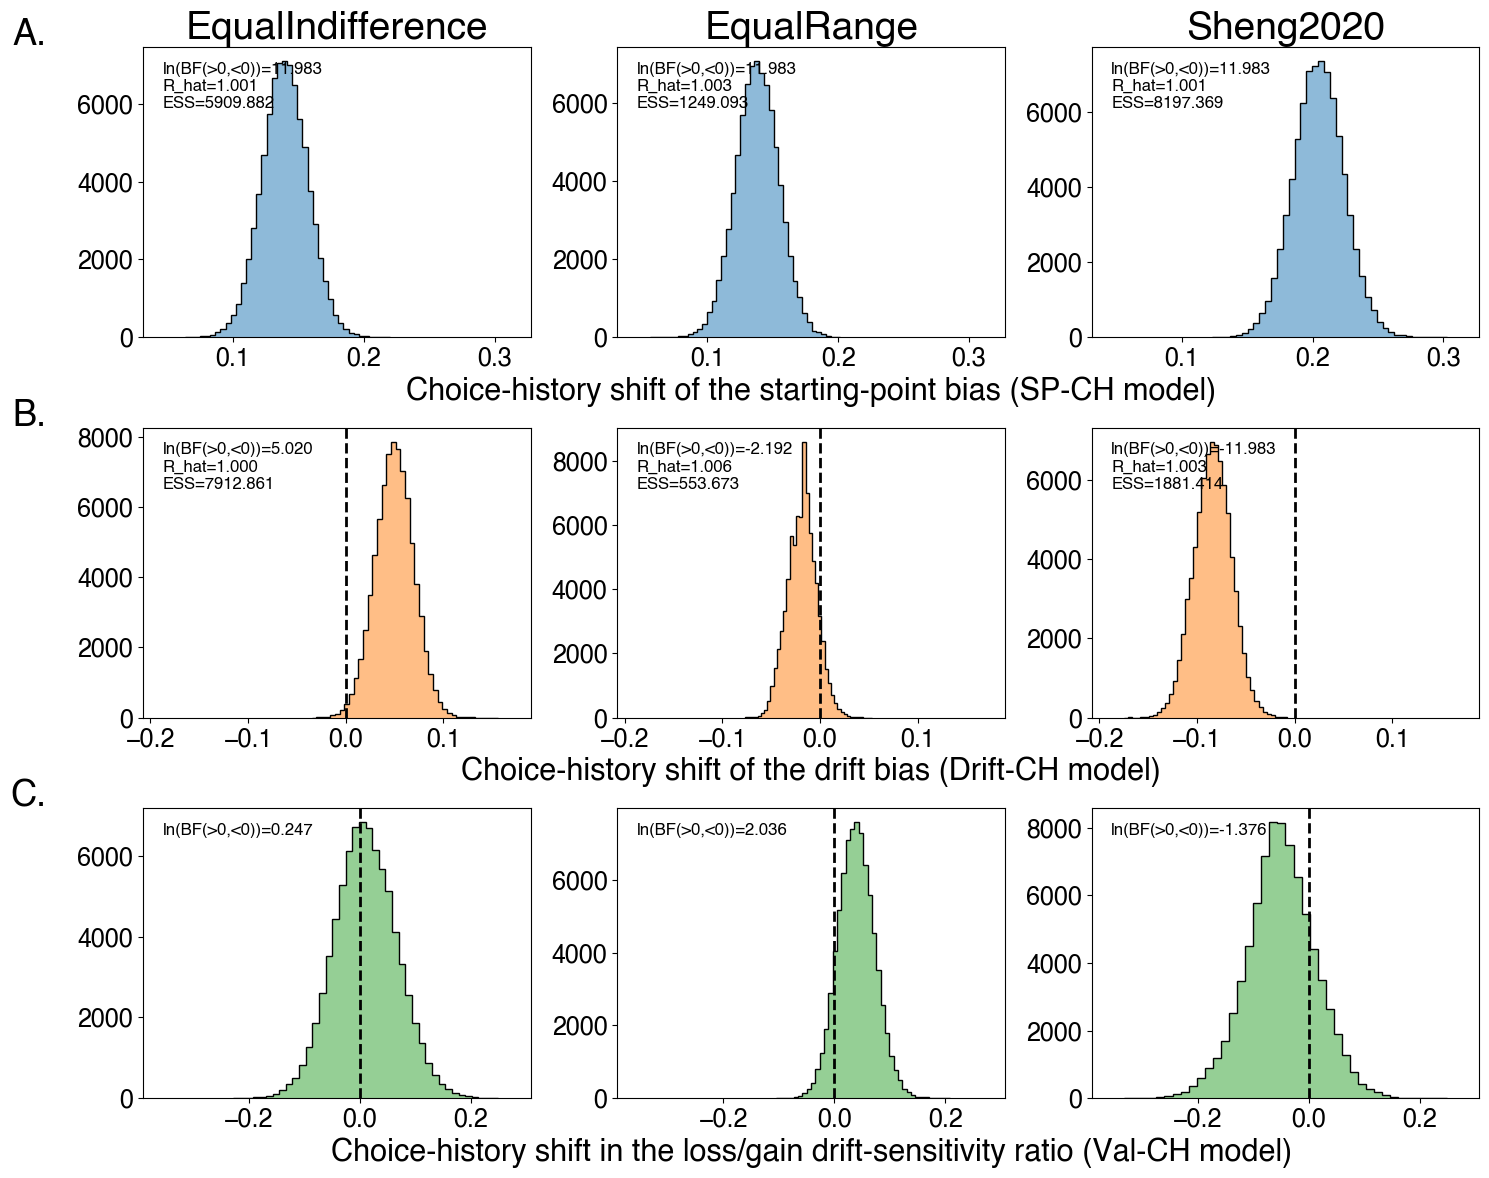

In [3]:
ROWS = [
    {
        "samples": lambda ds: pooled_samples(STP_MODEL, ds, "z_choice_prev1"),
        "convergence": lambda ds: get_convergence(STP_MODEL, ds, "z_choice_prev1"),
        "color": "#1f77b4",
        "xlabel": "Choice-history shift of the starting-point bias (SP-CH model)",
    },
    {
        "samples": lambda ds: pooled_samples(DRIFT_MODEL, ds, "v_choice_prev1"),
        "convergence": lambda ds: get_convergence(DRIFT_MODEL, ds, "v_choice_prev1"),
        "color": "#ff7f0e",
        "xlabel": "Choice-history shift of the drift bias (Drift-CH model)",
    },
    {
        "samples": lambda ds: loss_gain_ratio_diff_samples(ds),
        "convergence": None,
        "color": "#2ca02c",
        "xlabel": "Choice-history shift in the loss/gain drift-sensitivity ratio (Val-CH model)",
    },
]

ROW_LABELS = ["A.", "B.", "C."]

fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(15, 12), squeeze=False)

for row_idx, row in enumerate(ROWS):
    samples_by_dataset = {ds: row["samples"](ds) for ds in DATASETS}

    lo = min(s.min() for s in samples_by_dataset.values())
    hi = max(s.max() for s in samples_by_dataset.values())
    margin = 0.1 * (hi - lo)
    xlim = (lo - margin, hi + margin)

    for col, ds in enumerate(DATASETS):
        ax = axes[row_idx, col]
        rhat_ess = row["convergence"](ds) if row["convergence"] else None
        plot_row_hist(ax, samples_by_dataset[ds], row["color"], xlim, rhat_ess)

        if row_idx == 0:
            ax.set_title(DATASET_LABELS.get(ds, ds))
        if col == 1:
            ax.set_xlabel(row["xlabel"])

    axes[row_idx, 0].text(-0.25, 1.1, ROW_LABELS[row_idx], transform=axes[row_idx, 0].transAxes,
                          fontsize=26, fontweight="bold", va="top", ha="right")

plt.tight_layout()
fig.savefig("saved/figureS9.svg", dpi=300, bbox_inches="tight")
plt.show()